# Exploração (EDA) — B2W-Reviews01

Só EDA: toda lógica vem de `src/` (DEVELOPMENT.md §6.1). Requer `make install-eda` e `make data`.

Estatísticas de tamanho usam **só o treino** (o teste é intocável, §4.3).

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import transformers
from transformers import AutoTokenizer

from src.config import DataConfig, load_config
from src.data_loader import read_splits
from src.preprocessing import (
    LABELS,
    class_counts,
    length_percentiles,
    sample_per_class,
    token_lengths,
)

In [2]:
# Caminhos da config são relativos à raiz do repositório.
if Path.cwd().name == "notebooks":
    os.chdir("..")

TOKENIZER_NAME = "neuralmind/bert-base-portuguese-cased"  # encoder da Fase 3
transformers.logging.set_verbosity_error()  # medimos o tamanho real, sem truncar
pd.set_option("display.max_colwidth", 200)

cfg = load_config("configs/data.yaml", DataConfig)
splits = read_splits(cfg.processed_dir)
train = splits["train"]
{name: len(df) for name, df in splits.items()}

{'train': 101340, 'val': 12667, 'test': 12668}

## 1. Distribuição de classes

In [3]:
counts = pd.DataFrame({name: class_counts(df["label"]) for name, df in splits.items()})
pct = (counts / counts.sum() * 100).round(2)
pd.concat({"n": counts, "%": pct}, axis=1)

n                  %              
          train   val  test  train    val   test
negativo  26074  3259  3260  25.73  25.73  25.73
neutro    12671  1584  1584  12.50  12.50  12.50
positivo  62595  7824  7824  61.77  61.77  61.76

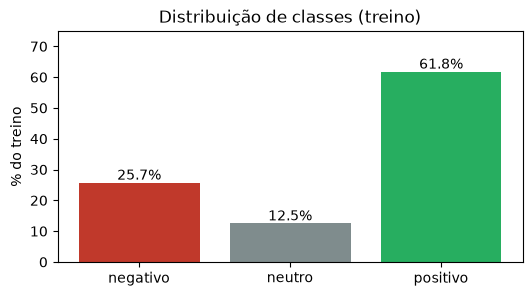

In [4]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(LABELS, pct["train"], color=["#c0392b", "#7f8c8d", "#27ae60"])
ax.set_ylabel("% do treino")
ax.set_title("Distribuição de classes (treino)")
for i, v in enumerate(pct["train"]):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center")
ax.set_ylim(0, 75)
plt.show()

## 2. Tamanho em tokens (tokenizer do BERTimbau, treino)

Inclui `[CLS]` e `[SEP]`: é o comprimento que o encoder realmente recebe.

In [5]:
tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_NAME)


def tokenize(batch: list[str]) -> list[list[int]]:
    return tokenizer(batch, add_special_tokens=True)["input_ids"]


lengths = token_lengths(train["text"].tolist(), tokenize)
pcts = length_percentiles(lengths)
pcts

{50: 26, 90: 70, 95: 95, 99: 177}

In [6]:
by_class = pd.DataFrame(
    {label: length_percentiles(lengths[(train["label"] == label).to_numpy()]) for label in LABELS}
)
by_class.index.name = "percentil"
by_class

,negativo,neutro,positivo
percentil,,,
50,38,26,23
90,97,70,55
95,129,96,74
99,221,178,138


In [7]:
pd.Series(
    {f"> {n} tokens": f"{(lengths > n).mean():.2%}" for n in (64, 128, 256, 512)},
    name="fração do treino",
)

> 64 tokens     11.71%
> 128 tokens     2.37%
> 256 tokens     0.36%
> 512 tokens     0.04%
Name: fração do treino, dtype: str

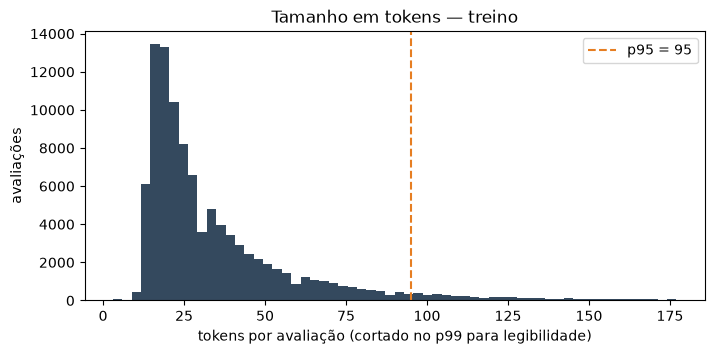

In [8]:
p95, p99 = pcts[95], pcts[99]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(lengths[lengths <= p99], bins=60, color="#34495e")
ax.axvline(p95, color="#e67e22", linestyle="--", label=f"p95 = {p95}")
ax.set_xlabel("tokens por avaliação (cortado no p99 para legibilidade)")
ax.set_ylabel("avaliações")
ax.set_title("Tamanho em tokens — treino")
ax.legend()
plt.show()

## 3. Exemplos por classe (3 por classe, amostra com a seed da config)

In [9]:
sample_per_class(train, n=3, seed=cfg.seed)[["label", "rating", "text"]]

,label,rating,text
5587,negativo,2,"O produto tem as peças pra fazer regulagem, porém não funciona"
9461,negativo,1,"Nunca recebi o produto, ainda aguardo uma posição da empresa, mas até o momento não houve uma satisfação sobre a entrega."
11803,negativo,1,"Pouco alcance e desconfortável quando nos olhos. Vocês pedem para fazer avaliação dos produtos, mas quando escrevemos o suficiente do produto e teclo em avaliar aparece : "" o texto de analise é mu..."
42410,neutro,3,"O produto é bom, não é igual ao original , mas atende perfeitamente a necessidade"
13695,neutro,3,Correspondeu às minhas expectativas! Fiquei muito satisfeita.
16870,neutro,3,"Tapete é mais simples do que parece na foto, a base é lisa e pintada. Mesmo assim o nosso bebê adorou. A entrega foi muito demorada, extrapolou o prazo, serviço dos correios está muito ruim."
27863,positivo,5,Aparelho com acabamento e construção top e com desempenho ótimo e seu ponto mais forte é a sua bateria que vem durando até 3 dias. Entrega rápida antes do prazo tudo certo. Entre os intermediários...
26005,positivo,4,Ótimo produto e de bom design e de acordo com o prometido.
83489,positivo,5,"Produto de qualidade excelente, fácil manuseio. recomendo a todos!"


## Conclusões

Todos os números abaixo vêm dos outputs das células acima (treino, salvo indicação).

1. **Desbalanceamento confirmado.** 61,8% positivo, 25,7% negativo e só 12,5% neutro. O split estratificado preserva as proporções em treino/val/teste (diferença ≤ 0,01 p.p.). Isso sustenta o **macro-F1** como métrica principal (ADR-001) e o subconjunto **balanceado** para os LLMs (§4.4).
2. **Textos são curtos.** Mediana de 26 tokens, **p95 = 95**, p99 = 177. Só 2,37% do treino passa de 128 tokens e 0,04% passa de 512.
3. **Negativos são os mais longos** (p95: 129 negativo vs. 96 neutro vs. 74 positivo). Clientes insatisfeitos explicam mais. Consequência: truncar afeta primeiro a classe negativa.
4. **`max_length` recomendado para o BERTimbau (Fase 3): 128.** Cobre ~97,6% do treino e ~95% dos negativos. Ir a 512 cobriria os 2,4% restantes a um custo de atenção ~16x maior (quadrático no comprimento).
5. **Para a QLoRA (Fase 5) esse número não transfere direto.** O LLM tem outro tokenizer e o prompt de instrução soma tokens fixos. Medir de novo com o tokenizer do modelo escolhido no ADR-002. O teto de 256 da §10 parece folgado diante destes dados.
6. **Ruído na classe neutra.** A nota 3 nem sempre é neutra no texto: há exemplos com elogio claro ("Correspondeu às minhas expectativas! Fiquei muito satisfeita.") e avaliações mistas (produto bom, entrega ruim). Isso limita o F1 alcançável no neutro e deve aparecer na análise de erros da Fase 6.
